# Análise estatística — produção de hemodiálise e internações por insuficiência renal no SUS

**Escopo final:** painel local SIA/SIH/IBGE de 2024–2025; unidade UF-mês. A conclusão do estudo não depende de novos insumos externos.

A comparação principal usa janeiro–outubro de cada ano. A estatística entrega magnitude das mudanças, distribuição territorial, intensidade bruta de produção por população, associações exploratórias e comparação retrospectiva de previsões SIA de um mês à frente. APAC e N18 ficam excluídos. O nome do arquivo mantém DRC por continuidade, mas N17–N19 não é uma medida específica de DRC.


## 1. Apresentação do projeto e problema

A doença renal crônica demanda atenção contínua na rede SUS. O projeto investiga como dois registros administrativos se distribuem no território e no tempo: a produção aprovada de hemodiálise (SIA/SUS) e as internações por insuficiência renal N17–N19 (SIH/TabNet).

**Problema:** os volumes variam entre UFs e competências, mas a leitura exige controle de cobertura, tratamento explícito de dados ausentes e métodos que não confundam registros agregados com pessoas atendidas.

**Variáveis principais:** UF, região, ano, mês, quantidade aprovada SIA, internações SIH, status de cobertura SIH e população IBGE anual. A unidade analítica é UF-mês.

**Objetivo final:** entregar uma análise reproduzível, clara e visual dos padrões observados, da incerteza estatística e de uma projeção exploratória da produção SIA.

**Etapas do trabalho:** (1) leitura e validação; (2) imputação documentada; (3) descrição; (4) probabilidade; (5) inferência; (6) comparação de modelos; (7) comunicação dos limites e conclusões.

## 2. Objetivo, perguntas e limites

**Objetivo geral:** descrever a variação territorial e temporal dos registros administrativos de hemodiálise e de internações por insuficiência renal, comparando janeiro–outubro de 2024 e 2025.

**Perguntas:** (i) como se distribuem as variáveis principais; (ii) qual a probabilidade empírica de aumento por UF; (iii) há evidência exploratória de mudança direcional e associação ecológica; (iv) qual modelo simples melhor prevê a produção mensal SIA.

> **Limites:** cada linha representa uma UF-mês, não uma pessoa. SIA mede quantidade aprovada; SIH N17–N19 é uma categoria diagnóstica ampla. Resultados são ecológicos, exploratórios e não estimam efetividade ou causalidade.

## 3. Preparação visual e leitura da base

A paleta mantém SIA em azul, SIH em laranja e resultados de apoio em verde.

In [1]:
from pathlib import Path
from math import sqrt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

sns.set_theme(style='whitegrid', context='notebook')
CORES = {'sia': '#1F5A99', 'sih': '#E07A32', 'destaque': '#2A9D8F', 'alerta': '#C44536', 'cinza': '#5B6470'}
MESES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']

candidatos = [Path.cwd() / 'Trabalho-final', Path.cwd(), Path.cwd().parent]
projeto = next(c.resolve() for c in candidatos if (c / 'Dados').is_dir())
arquivo_base = projeto / 'Dados/03_bases_analiticas/descritiva_territorial_2024_2025/painel_descritivo_uf_mes_2024_2025.csv'

painel = pd.read_csv(arquivo_base, sep=';', encoding='utf-8-sig')
painel['data'] = pd.to_datetime(painel['competencia'] + '-01')
painel['mes_nome'] = pd.Categorical(painel['mes'].map(dict(enumerate(MESES, start=1))), categories=MESES, ordered=True)

assert painel.shape[0] == 648
assert painel[['cod_uf', 'ano', 'mes']].duplicated().sum() == 0
assert painel['sia_hemodialise_quantidade_aprovada'].ge(0).all(), (
    'sia_hemodialise_quantidade_aprovada deve conter apenas valores não negativos.'
)
assert painel['sih_n17_n19_internacoes_tabnet'].dropna().ge(0).all(), (
    'sih_n17_n19_internacoes_tabnet deve conter apenas valores observados não negativos.'
)
print(f'Base carregada: {painel.shape[0]} linhas UF-mês, {painel.sigla_uf.nunique()} UFs e {painel.data.nunique()} competências.')

Base carregada: 648 linhas UF-mês, 27 UFs e 24 competências.


## 4. Tratamento de dado ausente: imputação sazonal ajustada

Há uma única ausência: internações SIH de Roraima em dezembro de 2025. A base original é preservada; cria-se apenas uma cópia analítica.

O método usa o valor de dezembro de 2024 da mesma UF, ajustado pela razão entre os totais observados de janeiro–outubro de 2025 e 2024 em Roraima. A janela evita novembro, cuja maturidade está em verificação. A imputação é apenas uma sensibilidade; tabelas, gráficos e testes principais mantêm a ausência original.

In [2]:
painel_analitico = painel.copy()
mascara_ausente = painel_analitico['sih_n17_n19_internacoes_tabnet'].isna()
assert mascara_ausente.sum() == 1

rr_2024 = painel.query("sigla_uf == 'RR' and ano == 2024 and mes <= 10")['sih_n17_n19_internacoes_tabnet'].sum()
rr_2025 = painel.query("sigla_uf == 'RR' and ano == 2025 and mes <= 10")['sih_n17_n19_internacoes_tabnet'].sum()
dezembro_rr_2024 = painel.query("sigla_uf == 'RR' and ano == 2024 and mes == 12")['sih_n17_n19_internacoes_tabnet'].iloc[0]
fator_crescimento_rr = rr_2025 / rr_2024
valor_imputado = int(round(dezembro_rr_2024 * fator_crescimento_rr))

painel_analitico['sih_origem'] = np.where(mascara_ausente, 'imputado_sazonal', 'observado')
painel_analitico.loc[mascara_ausente, 'sih_n17_n19_internacoes_tabnet'] = valor_imputado

registro_imputacao = painel_analitico.loc[mascara_ausente, ['sigla_uf', 'competencia', 'sih_n17_n19_internacoes_tabnet', 'sih_origem']].copy()
registro_imputacao['fator_crescimento_jan_out'] = fator_crescimento_rr
display(registro_imputacao.style.format({'fator_crescimento_jan_out': '{:.3f}'}))
impacto_sensibilidade = pd.DataFrame([{
    'total_SIH_2025_observado': painel.query('ano == 2025')['sih_n17_n19_internacoes_tabnet'].sum(),
    'total_SIH_2025_com_imputacao': painel_analitico.query('ano == 2025')['sih_n17_n19_internacoes_tabnet'].sum(),
}])
display(impacto_sensibilidade.style.format('{:,.0f}'))
print('A cópia imputada serve apenas para sensibilidade; a fonte original permanece sem alteração.')

,sigla_uf,competencia,sih_n17_n19_internacoes_tabnet,sih_origem,fator_crescimento_jan_out
95,RR,2025-12,27.000000,imputado_sazonal,0.704


,total_SIH_2025_observado,total_SIH_2025_com_imputacao
0,"153,083","153,110"


A cópia imputada serve apenas para sensibilidade; a fonte original permanece sem alteração.


## 5. Qualidade e cobertura

Na leitura da base, a quantidade aprovada SIA e as internações observadas SIH são verificadas para garantir valores não negativos.

A ausência SIH é tratada como ausente, nunca como zero. A janela principal usa janeiro–outubro para evitar a possível incompletude do SIH em novembro/dezembro de 2025.

In [3]:
cobertura = (painel.assign(sih_observado=painel['sih_n17_n19_internacoes_tabnet'].notna())
            .groupby(['ano', 'mes'], as_index=False)
            .agg(ufs_sih_observadas=('sih_observado', 'sum'), ufs_esperadas=('sigla_uf', 'nunique')))
cobertura['cobertura_sih_pct'] = 100 * cobertura['ufs_sih_observadas'] / cobertura['ufs_esperadas']

display(cobertura.tail(6))
print('Células SIH ausentes:', painel.loc[painel['sih_n17_n19_internacoes_tabnet'].isna(), ['sigla_uf', 'competencia']].to_dict('records'))

,ano,mes,ufs_sih_observadas,ufs_esperadas,cobertura_sih_pct
18,2025,7,27,27,100.000000
19,2025,8,27,27,100.000000
20,2025,9,27,27,100.000000
21,2025,10,27,27,100.000000
22,2025,11,27,27,100.000000
23,2025,12,26,27,96.296296


Células SIH ausentes: [{'sigla_uf': 'RR', 'competencia': '2025-12'}]


### Variáveis selecionadas e exclusões

| Campo | Uso na análise | Decisão e justificativa |
|---|---|---|
| `sia_hemodialise_quantidade_aprovada` | Descrição, probabilidade, inferência e previsão | Mantido: é o indicador de produção ambulatorial disponível e completo. |
| `sih_n17_n19_internacoes_tabnet` | Descrição, probabilidade e inferência | Mantido observado; imputação só em sensibilidade. Excluído da previsão por possível incompletude em nov/dez 2025. |
| `populacao_ibge_referencia_anual` | Denominador para taxa ecológica por 100 mil | Mantido somente em agregações anuais; a referência é julho, não mensal. |
| `regiao`, `ano`, `mes`, `competencia` | Estratificação, comparação e eixo temporal | Mantidos: definem o contexto territorial e temporal. |
| `cod_uf`, `sigla_uf`, `uf` | Chave e rótulo | Não entram como preditores: identificam a observação, sem significado numérico. |
| N18 e APAC | Fora do painel final | Excluídos: auditorias pendentes e ausência de vínculo individual válido. |

## 6. Análise descritiva

As medidas abaixo resumem as 648 observações UF-mês. Mediana e intervalo interquartil são mostrados porque contagens por UF tendem a ser assimétricas. A taxa anual é **Quantidade aprovada por 100 mil habitantes**: permite comparação territorial, mas não representa pacientes, cobertura ou sessões individuais.

,n,mean,std,min,q1,mediana,q3,max
SIA: quantidade aprovada,648.0,57556.9,70123.9,3030.0,14555.0,32175.5,75866.5,366554.0
SIH: internações N17–N19,647.0,478.5,605.2,1.0,120.0,251.0,565.0,3170.0


,sigla_uf,uf,regiao,ano,sia_quantidade_aprovada,populacao_ibge_referencia_anual,taxa_sia_por_100_mil
32,PI,Piauí,Nordeste,2024,"396,540","3,375,646","11,747.1"
38,RN,Rio Grande do Norte,Nordeste,2024,"386,293","3,446,071","11,209.7"
30,PE,Pernambuco,Nordeste,2024,"1,032,594","9,539,029","10,824.9"
20,MG,Minas Gerais,Sudeste,2024,"2,275,652","21,322,691","10,672.4"
10,CE,Ceará,Nordeste,2024,"959,613","9,233,656","10,392.6"
2,AL,Alagoas,Nordeste,2024,"314,647","3,220,104","9,771.3"
22,MS,Mato Grosso do Sul,Centro-Oeste,2024,"282,722","2,901,895","9,742.7"
8,BA,Bahia,Nordeste,2024,"1,387,682","14,850,513","9,344.3"
50,SP,São Paulo,Sudeste,2024,"4,014,211","45,973,194","8,731.6"
0,AC,Acre,Norte,2024,"74,891","880,631","8,504.2"


,regiao,ano,sia_quantidade_aprovada,populacao_ibge_referencia_anual,taxa_sia_por_100_mil
0,Centro-Oeste,2024,"1,395,120","17,071,595","8,172.2"
2,Nordeste,2024,"5,523,144","57,112,096","9,670.7"
4,Norte,2024,"1,082,709","18,669,345","5,799.4"
6,Sudeste,2024,"7,997,448","88,617,693","9,024.7"
8,Sul,2024,"2,313,561","31,113,021","7,436.0"
1,Centro-Oeste,2025,"1,418,023","17,238,818","8,225.8"
3,Nordeste,2025,"5,759,293","57,244,485","10,060.9"
5,Norte,2025,"1,176,923","18,801,282","6,259.8"
7,Sudeste,2025,"8,273,695","88,825,643","9,314.5"
9,Sul,2025,"2,356,936","31,310,809","7,527.5"


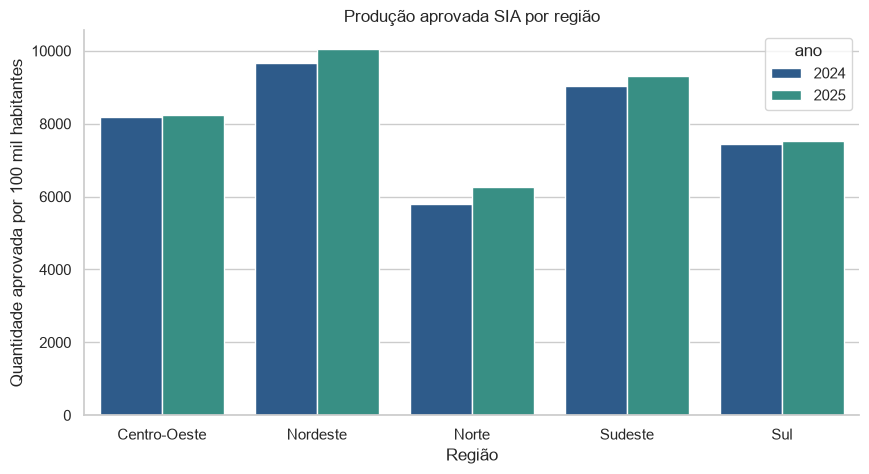

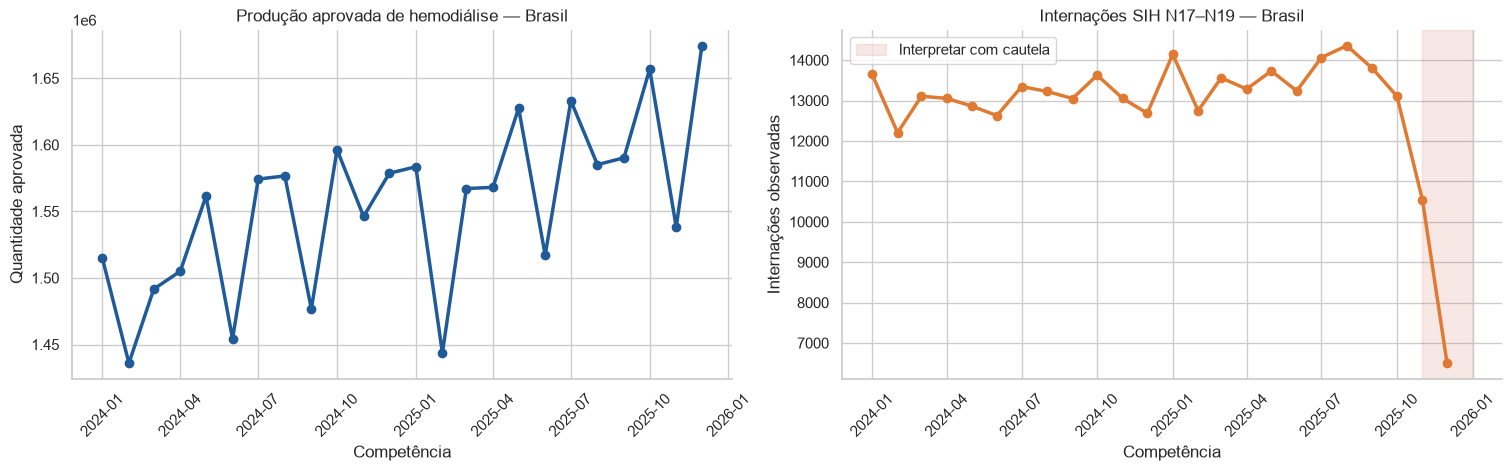

In [4]:
variaveis = ['sia_hemodialise_quantidade_aprovada', 'sih_n17_n19_internacoes_tabnet']
nomes = {'sia_hemodialise_quantidade_aprovada': 'SIA: quantidade aprovada', 'sih_n17_n19_internacoes_tabnet': 'SIH: internações N17–N19'}

resumo = (painel[variaveis].describe(percentiles=[.25, .5, .75]).T
          .rename(index=nomes, columns={'50%': 'mediana', '25%': 'q1', '75%': 'q3', 'count': 'n'})
          [['n', 'mean', 'std', 'min', 'q1', 'mediana', 'q3', 'max']].round(1))
display(resumo)

assert (painel.groupby(['sigla_uf', 'ano'])['populacao_ibge_referencia_anual'].nunique() == 1).all()
sia_anual_uf = (painel.groupby(['sigla_uf', 'uf', 'regiao', 'ano'], as_index=False)
                .agg(sia_quantidade_aprovada=('sia_hemodialise_quantidade_aprovada', 'sum'),
                     populacao_ibge_referencia_anual=('populacao_ibge_referencia_anual', 'first')))
sia_anual_uf['taxa_sia_por_100_mil'] = (
    100_000 * sia_anual_uf['sia_quantidade_aprovada'] / sia_anual_uf['populacao_ibge_referencia_anual']
)
display(sia_anual_uf.sort_values(['ano', 'taxa_sia_por_100_mil'], ascending=[True, False])
        .style.format({'sia_quantidade_aprovada': '{:,.0f}', 'populacao_ibge_referencia_anual': '{:,.0f}',
                       'taxa_sia_por_100_mil': '{:,.1f}'}))

taxa_sia_regional = (sia_anual_uf.groupby(['regiao', 'ano'], as_index=False)
                    .agg(sia_quantidade_aprovada=('sia_quantidade_aprovada', 'sum'),
                         populacao_ibge_referencia_anual=('populacao_ibge_referencia_anual', 'sum')))
taxa_sia_regional['taxa_sia_por_100_mil'] = (
    100_000 * taxa_sia_regional['sia_quantidade_aprovada'] / taxa_sia_regional['populacao_ibge_referencia_anual']
)
display(taxa_sia_regional.sort_values(['ano', 'regiao'])
        .style.format({'sia_quantidade_aprovada': '{:,.0f}', 'populacao_ibge_referencia_anual': '{:,.0f}',
                       'taxa_sia_por_100_mil': '{:,.1f}'}))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=taxa_sia_regional, x='regiao', y='taxa_sia_por_100_mil', hue='ano', palette=[CORES['sia'], CORES['destaque']], ax=ax)
ax.set(title='Produção aprovada SIA por região', xlabel='Região', ylabel='Quantidade aprovada por 100 mil habitantes')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

serie_brasil = (painel.groupby('data', as_index=False)
                .agg(sia=('sia_hemodialise_quantidade_aprovada', 'sum'),
                     sih=('sih_n17_n19_internacoes_tabnet', 'sum'),
                     ufs_sih=('sih_n17_n19_internacoes_tabnet', 'count')))
serie_brasil['rotulo'] = serie_brasil['data'].dt.strftime('%m/%Y')

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), layout='constrained')
axes[0].plot(serie_brasil['data'], serie_brasil['sia'], marker='o', color=CORES['sia'], linewidth=2.5)
axes[0].set(title='Produção aprovada de hemodiálise — Brasil', ylabel='Quantidade aprovada', xlabel='Competência')
axes[1].plot(serie_brasil['data'], serie_brasil['sih'], marker='o', color=CORES['sih'], linewidth=2.5)
axes[1].axvspan(pd.Timestamp('2025-11-01'), pd.Timestamp('2025-12-31'), color=CORES['alerta'], alpha=.12, label='Interpretar com cautela')
axes[1].set(title='Internações SIH N17–N19 — Brasil', ylabel='Internações observadas', xlabel='Competência')
axes[1].legend(frameon=True)
for ax in axes:
    ax.tick_params(axis='x', rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
plt.show()

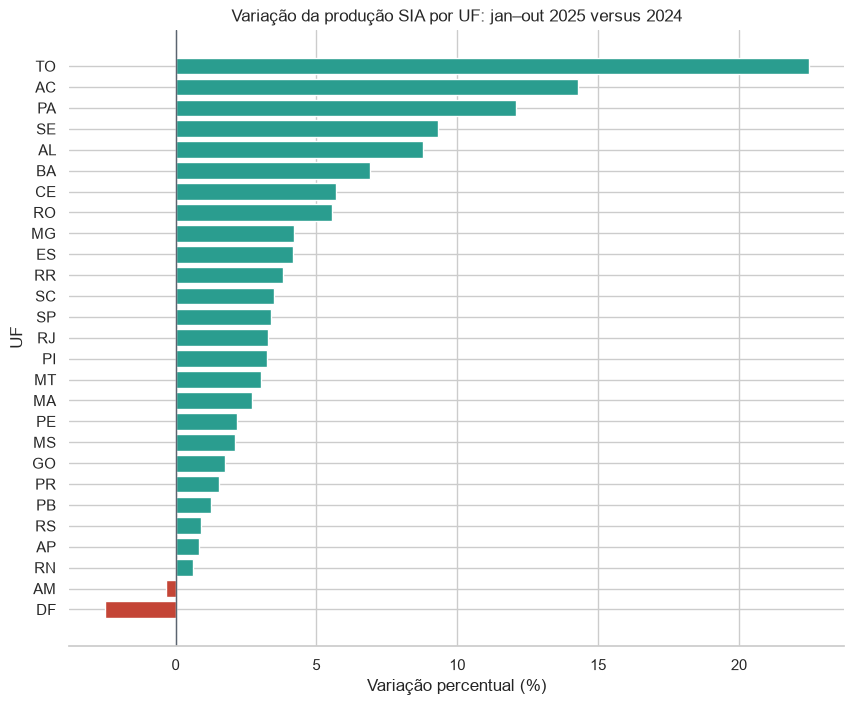

,sigla_uf,regiao,sia_variacao_absoluta,sia_variacao_pct,sih_variacao_absoluta,sih_variacao_pct
26,TO,Norte,15700.0,22.49,104.0,12.41
0,AC,Norte,8798.0,14.30,-18.0,-5.16
13,PA,Norte,51707.0,12.09,74.0,1.33
24,SE,Nordeste,13694.0,9.33,-67.0,-8.45
1,AL,Nordeste,22921.0,8.79,117.0,6.22
4,BA,Nordeste,79105.0,6.89,98.0,1.07
5,CE,Nordeste,45434.0,5.71,228.0,5.43
20,RO,Norte,6210.0,5.55,-53.0,-5.17
10,MG,Sudeste,79272.0,4.20,407.0,2.38
7,ES,Sudeste,12037.0,4.18,359.0,12.65


In [5]:
jan_out = painel.loc[painel['mes'].between(1, 10)].copy()
por_uf = (jan_out.groupby(['sigla_uf', 'uf', 'regiao', 'ano'], as_index=False)
          .agg(sia=('sia_hemodialise_quantidade_aprovada', 'sum'), sih=('sih_n17_n19_internacoes_tabnet', 'sum')))
comparacao = (por_uf.pivot(index=['sigla_uf', 'uf', 'regiao'], columns='ano', values=['sia', 'sih'])
              .reset_index())
comparacao.columns = ['sigla_uf', 'uf', 'regiao', 'sia_2024', 'sia_2025', 'sih_2024', 'sih_2025']
for medida in ['sia', 'sih']:
    comparacao[f'{medida}_variacao_absoluta'] = comparacao[f'{medida}_2025'] - comparacao[f'{medida}_2024']
    comparacao[f'{medida}_variacao_pct'] = 100 * (comparacao[f'{medida}_2025'] / comparacao[f'{medida}_2024'] - 1)

ordenado = comparacao.sort_values('sia_variacao_pct')
fig, ax = plt.subplots(figsize=(10, 8))
cores_barras = np.where(ordenado['sia_variacao_pct'] >= 0, CORES['destaque'], CORES['alerta'])
ax.barh(ordenado['sigla_uf'], ordenado['sia_variacao_pct'], color=cores_barras)
ax.axvline(0, color=CORES['cinza'], linewidth=1)
ax.set(title='Variação da produção SIA por UF: jan–out 2025 versus 2024', xlabel='Variação percentual (%)', ylabel='UF')
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.show()

colunas_comparacao = ['sigla_uf', 'regiao', 'sia_variacao_absoluta', 'sia_variacao_pct', 'sih_variacao_absoluta', 'sih_variacao_pct']
display(comparacao[colunas_comparacao].sort_values('sia_variacao_pct', ascending=False).round(2))

## 7. Aplicação de probabilidade

A probabilidade empírica é a proporção de UFs com aumento no período. O intervalo de confiança exato de 95% quantifica a incerteza dessa proporção entre as 27 UFs observadas; ele não transforma o painel em uma amostra aleatória do país.

Como as 27 UFs constituem o conjunto territorial observado, o intervalo binomial é condicionado a um modelo de referência e não representa erro amostral de um censo. A dependência espacial entre UFs limita esse modelo.

In [6]:
def proporcao_com_ic(valores):
    sucessos = int((valores > 0).sum())
    total = valores.notna().sum()
    ic = stats.binomtest(sucessos, total).proportion_ci(confidence_level=.95, method='exact')
    return pd.Series({'ufs_com_aumento': sucessos, 'ufs_validas': total, 'probabilidade_empirica': sucessos / total, 'ic95_inferior': ic.low, 'ic95_superior': ic.high})

probabilidades = pd.DataFrame({
    'SIA': proporcao_com_ic(comparacao['sia_variacao_pct']),
    'SIH': proporcao_com_ic(comparacao['sih_variacao_pct'])
}).T
display(probabilidades.style.format({'probabilidade_empirica': '{:.1%}', 'ic95_inferior': '{:.1%}', 'ic95_superior': '{:.1%}'}))

,ufs_com_aumento,ufs_validas,probabilidade_empirica,ic95_inferior,ic95_superior
SIA,25.000000,27.000000,92.6%,75.7%,99.1%
SIH,17.000000,27.000000,63.0%,42.4%,80.6%


## 8. Inferência estatística exploratória

O teste binomial de sinais verifica se aumentos e reduções entre UFs são igualmente frequentes. A correlação de Spearman avalia associação monotônica entre variações percentuais. Os testes são bilaterais, com nível de 5%, e têm interpretação exploratória.

A família de Holm neste caderno contém exatamente três testes: sinais SIA, sinais SIH e Spearman entre variações. P-valores ajustados em outras famílias do notebook 04 não são diretamente intercambiáveis.

,análise,estatistica_ou_positivos,negativos,p_valor,p_valor_holm,conclusao_exploratoria_5pct
0,Mudança direcional SIA,25.000,2.000000,5.648e-06,1.694e-05,Evidência contra H0
1,Mudança direcional SIH,17.000,10.000000,0.2478,0.4275,Sem evidência contra H0
2,Correlação Spearman: variação SIA × SIH,-0.247,nan,0.2137,0.4275,Sem evidência contra H0


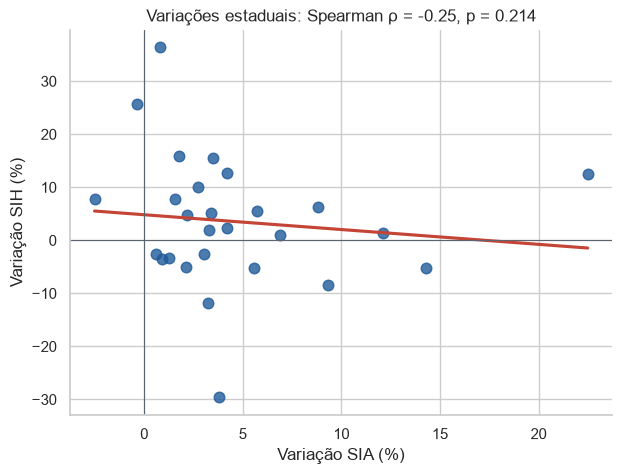

In [7]:
def teste_sinais(variacao):
    positivos = int((variacao > 0).sum())
    negativos = int((variacao < 0).sum())
    resultado = stats.binomtest(positivos, positivos + negativos, p=.5, alternative='two-sided')
    return positivos, negativos, resultado.pvalue

sia_pos, sia_neg, p_sia = teste_sinais(comparacao['sia_variacao_pct'])
sih_pos, sih_neg, p_sih = teste_sinais(comparacao['sih_variacao_pct'])
rho, p_rho = stats.spearmanr(comparacao['sia_variacao_pct'], comparacao['sih_variacao_pct'])

inferencias = pd.DataFrame([
    ['Mudança direcional SIA', sia_pos, sia_neg, p_sia],
    ['Mudança direcional SIH', sih_pos, sih_neg, p_sih],
    ['Correlação Spearman: variação SIA × SIH', rho, np.nan, p_rho],
], columns=['análise', 'estatistica_ou_positivos', 'negativos', 'p_valor'])
inferencias['p_valor_holm'] = multipletests(inferencias['p_valor'], method='holm')[1]
inferencias['conclusao_exploratoria_5pct'] = np.where(inferencias['p_valor_holm'] < .05, 'Evidência contra H0', 'Sem evidência contra H0')
display(inferencias.style.format({'estatistica_ou_positivos': '{:.3f}', 'p_valor': '{:.4g}', 'p_valor_holm': '{:.4g}'}))

fig, ax = plt.subplots(figsize=(7, 5))
sns.regplot(data=comparacao, x='sia_variacao_pct', y='sih_variacao_pct', ci=None, scatter_kws={'s': 58, 'color': CORES['sia']}, line_kws={'color': CORES['alerta']}, ax=ax)
ax.axhline(0, color=CORES['cinza'], linewidth=.8); ax.axvline(0, color=CORES['cinza'], linewidth=.8)
ax.set(title=f'Variações estaduais: Spearman ρ = {rho:.2f}, p = {p_rho:.3f}', xlabel='Variação SIA (%)', ylabel='Variação SIH (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

### Comparação regional: avaliação de ANOVA

A comparação usa a variação percentual SIA de janeiro–outubro entre 2024 e 2025. Cada UF aparece uma única vez. Primeiro, são verificados normalidade por região (Shapiro–Wilk) e homogeneidade das variâncias (Levene). A ANOVA é exibida como referência; quando os pressupostos falham, a conclusão usa Kruskal–Wallis. Os grupos regionais são pequenos, portanto a leitura é complementar e exploratória.

Kruskal–Wallis compara distribuições por postos; com dispersões diferentes, não isola diferenças de medianas. Não significância não demonstra igualdade. Sul (3 UFs) e Centro-Oeste (4 UFs) têm os menores grupos.

,regiao,p_shapiro
0,Centro-Oeste,0.1525
1,Nordeste,0.3359
2,Norte,0.5147
3,Sudeste,0.0794
4,Sul,0.4504


,p_Levene,p_ANOVA,p_Kruskal_Wallis,método_para_interpretação
0,0.0370,0.1580,0.2484,Kruskal–Wallis


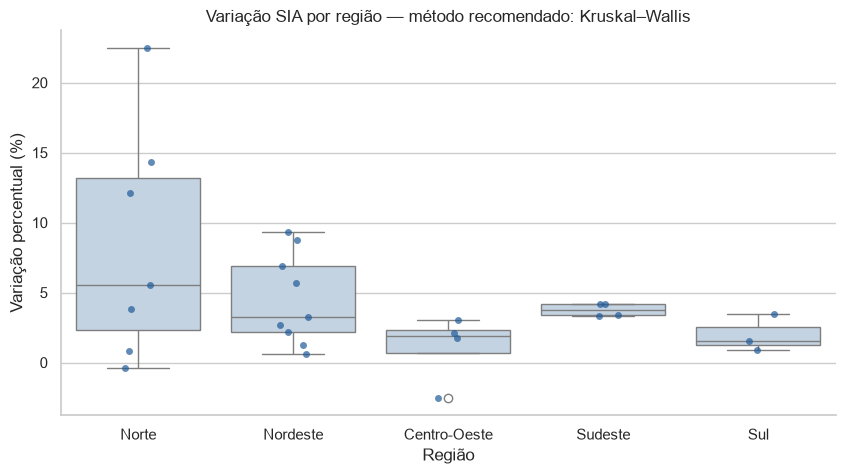

In [8]:
variacao_regional = comparacao[['sigla_uf', 'regiao', 'sia_variacao_pct']].copy()
grupos_regionais = [grupo['sia_variacao_pct'].to_numpy() for _, grupo in variacao_regional.groupby('regiao', sort=False)]
normalidade = (variacao_regional.groupby('regiao')['sia_variacao_pct']
               .apply(lambda valores: stats.shapiro(valores).pvalue)
               .rename('p_shapiro').reset_index())
p_levene = stats.levene(*grupos_regionais, center='median').pvalue
p_anova = stats.f_oneway(*grupos_regionais).pvalue
p_kruskal = stats.kruskal(*grupos_regionais).pvalue
pressupostos_atendidos = bool((normalidade['p_shapiro'] > .05).all() and p_levene > .05)
metodo_recomendado = 'ANOVA clássica' if pressupostos_atendidos else 'Kruskal–Wallis'

display(normalidade.style.format({'p_shapiro': '{:.4f}'}))
display(pd.DataFrame([{
    'p_Levene': p_levene, 'p_ANOVA': p_anova, 'p_Kruskal_Wallis': p_kruskal,
    'método_para_interpretação': metodo_recomendado
}]).style.format({'p_Levene': '{:.4f}', 'p_ANOVA': '{:.4f}', 'p_Kruskal_Wallis': '{:.4f}'}))

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=variacao_regional, x='regiao', y='sia_variacao_pct', color='#BFD3E6', ax=ax)
sns.stripplot(data=variacao_regional, x='regiao', y='sia_variacao_pct', color=CORES['sia'], alpha=.7, ax=ax)
ax.set(title=f'Variação SIA por região — método recomendado: {metodo_recomendado}', xlabel='Região', ylabel='Variação percentual (%)')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 9. Previsão exploratória da produção SIA

A previsão usa somente SIA, cuja série está completa. SIH não é modelado porque novembro/dezembro de 2025 exigem investigação de maturidade. Há somente 24 competências; portanto, a projeção é didática e exploratória, não operacional.

**Modelos candidatos:** média móvel de três meses, tendência linear e ingênuo sazonal (mesmo mês do ano anterior). A validação é de origem móvel: cada mês de 2025 é previsto apenas com competências anteriores. O melhor modelo é o de menor MAPE; em empate, menor MAE.

São 12 previsões de um mês à frente, com histórico crescente. O MAPE dessa janela não valida os 12 meses projetados a partir de dezembro de 2025. A seleção e a avaliação usam a mesma janela, sem teste final independente. A cobertura das competências SIA não comprova encerramento administrativo ou ausência de revisões.

In [9]:
sia_mensal = serie_brasil[['data', 'sia']].sort_values('data').reset_index(drop=True)
serie_completa = sia_mensal['sia'].to_numpy(dtype=float)

def previsao_media_movel(serie, horizonte, janela=3):
    historico = list(serie.astype(float))
    previsoes = []
    for _ in range(horizonte):
        previsao = np.mean(historico[-janela:])
        previsoes.append(previsao)
        historico.append(previsao)
    return np.array(previsoes)

def previsao_tendencia_linear(serie, horizonte):
    x = np.arange(len(serie))
    inclinacao, intercepto = np.polyfit(x, serie, 1)
    return intercepto + inclinacao * np.arange(len(serie), len(serie) + horizonte)

def previsao_sazonal_ingenua(serie, horizonte):
    historico = list(serie.astype(float))
    previsoes = []
    for _ in range(horizonte):
        previsao = historico[-12]
        previsoes.append(previsao)
        historico.append(previsao)
    return np.array(previsoes)

geradores = {
    'Média móvel (3 meses)': previsao_media_movel,
    'Tendência linear': previsao_tendencia_linear,
    'Ingênuo sazonal': previsao_sazonal_ingenua,
}
previsoes_validacao = {modelo: [] for modelo in geradores}
observados_validacao = []
for indice in range(12, len(serie_completa)):
    historico = serie_completa[:indice]
    observados_validacao.append(serie_completa[indice])
    for modelo, gerador in geradores.items():
        previsoes_validacao[modelo].append(gerador(historico, 1)[0])

observados_validacao = np.array(observados_validacao)

metricas = []
for modelo, previsao in previsoes_validacao.items():
    erro = observados_validacao - np.array(previsao)
    metricas.append({'modelo': modelo, 'MAE': np.mean(np.abs(erro)), 'RMSE': sqrt(np.mean(erro ** 2)), 'MAPE_pct': 100 * np.mean(np.abs(erro / observados_validacao))})
metricas = pd.DataFrame(metricas).sort_values(['MAPE_pct', 'MAE']).reset_index(drop=True)
melhor_modelo = metricas.loc[0, 'modelo']
display(metricas.style.format({'MAE': '{:,.0f}', 'RMSE': '{:,.0f}', 'MAPE_pct': '{:.2f}%'}).highlight_min(subset=['MAE', 'RMSE', 'MAPE_pct'], color='#D9EAD3'))
print(f'Modelo selecionado: {melhor_modelo}. Critério: menor MAPE e, em empate, menor MAE.')

,modelo,MAE,RMSE,MAPE_pct
0,Tendência linear,"46,849","62,453",3.01%
1,Média móvel (3 meses),"55,276","65,864",3.53%
2,Ingênuo sazonal,"57,400","65,882",3.59%


Modelo selecionado: Tendência linear. Critério: menor MAPE e, em empate, menor MAE.


,mes,previsao_sia
0,01/2026,"1,625,257"
1,02/2026,"1,630,955"
2,03/2026,"1,636,653"
3,04/2026,"1,642,351"
4,05/2026,"1,648,048"
5,06/2026,"1,653,746"
6,07/2026,"1,659,444"
7,08/2026,"1,665,142"
8,09/2026,"1,670,839"
9,10/2026,"1,676,537"


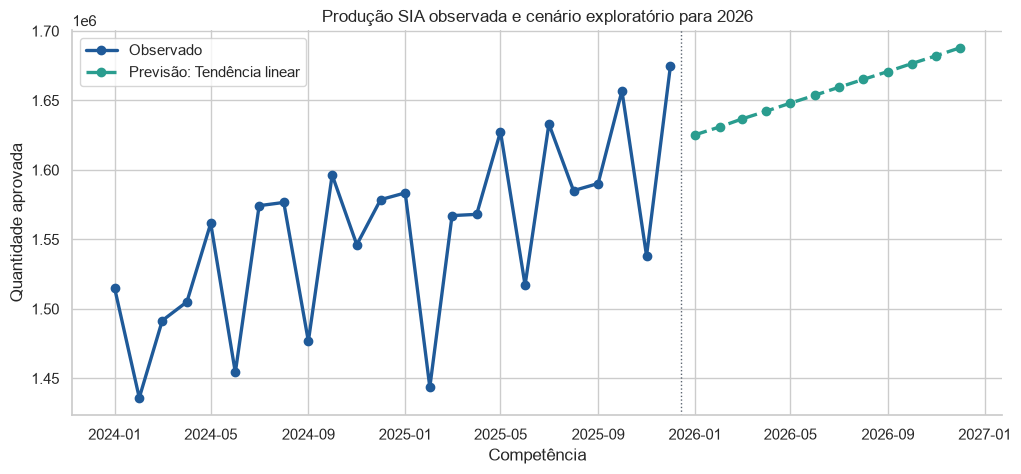

In [10]:
if melhor_modelo == 'Média móvel (3 meses)':
    previsao_2026 = previsao_media_movel(serie_completa, 12)
elif melhor_modelo == 'Tendência linear':
    previsao_2026 = previsao_tendencia_linear(serie_completa, 12)
else:
    previsao_2026 = previsao_sazonal_ingenua(serie_completa, 12)

futuro = pd.DataFrame({'data': pd.date_range('2026-01-01', periods=12, freq='MS'), 'previsao_sia': previsao_2026})
display(futuro.assign(mes=lambda x: x['data'].dt.strftime('%m/%Y')).loc[:, ['mes', 'previsao_sia']].style.format({'previsao_sia': '{:,.0f}'}))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(sia_mensal['data'], sia_mensal['sia'], color=CORES['sia'], marker='o', linewidth=2.4, label='Observado')
ax.plot(futuro['data'], futuro['previsao_sia'], color=CORES['destaque'], marker='o', linestyle='--', linewidth=2.4, label=f'Previsão: {melhor_modelo}')
ax.axvline(pd.Timestamp('2025-12-15'), color=CORES['cinza'], linestyle=':', linewidth=1)
ax.set(title='Produção SIA observada e cenário exploratório para 2026', xlabel='Competência', ylabel='Quantidade aprovada')
ax.legend(frameon=True)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

## 10. Síntese e comunicação dos resultados

Na janela janeiro–outubro, SIA cresceu 3,85% e SIH N17–N19 cresceu 4,04% em 2025 frente a 2024. Houve aumento SIA em 25/27 UFs (92,6%; IC exato de referência: 75,7%–99,1%) e SIH em 17/27 (63,0%; 42,4%–80,6%). Os intervalos são condicionados ao modelo binomial; não representam erro amostral de um censo territorial.

Na família de três testes deste caderno, sinais SIA apresentou p-Holm ≈ 0,000017; sinais SIH, p-Holm ≈ 0,427. A correlação entre variações foi ρ = −0,247 (p bruto ≈ 0,214; p-Holm ≈ 0,427). Há evidência exploratória de predomínio de aumento SIA; não há evidência suficiente de mudança direcional SIH ou de associação monotônica entre variações. Isso não demonstra estabilidade ou independência.

Levene indicou heterogeneidade regional (p=0,037). Kruskal–Wallis (p=0,248) não identificou evidência suficiente de diferença entre distribuições regionais; grupos pequenos e dispersões distintas limitam a interpretação. Não se conclui igualdade de regiões ou medianas.

A sensibilidade imputou 27 internações para RR/dezembro de 2025 (fator jan–out: 0,704), sem alterar resultados principais. Ela não resolve a possível incompletude SIH em novembro/dezembro.

A tendência linear apresentou menor MAPE (3,01%), MAE de 46.849 e RMSE de 62.453 unidades de quantidade aprovada. Essas métricas avaliam previsões de um mês à frente em 2025 e não garantem precisão para o cenário de 12 meses de 2026. Não houve conjunto final independente após a seleção.

**Conclusão:** os resultados descrevem registros territoriais e não estimam pacientes, acesso, prevalência, efetividade ou causalidade. N17–N19 inclui insuficiência renal aguda, crônica e não especificada; não é indicador específico de DRC. APAC e N18 seguem fora da análise principal.

**Para concluir a entrega:** revisar visualmente tabelas e gráficos, consolidar o relatório acadêmico e executar/salvar a versão final pelo kernel Jupyter com registro do ambiente e da base. O detalhamento está nas seções 11 e 12 do plano. Novas extrações SIH/SIA e eventual reabertura APAC/N18 são possibilidades de pesquisa futura, fora dos critérios de conclusão desta entrega.


**Resposta final com os dados disponíveis:** o volume nacional cresceu em janeiro–outubro (SIA: +585.014; SIH: +5.284). O aumento SIA foi disseminado em 25 UFs, enquanto o SIH apresentou maior heterogeneidade direcional. Rankings, variações absolutas/percentuais e produção SIA por população descrevem os contrastes territoriais observados. Não se identificou evidência suficiente de associação entre as variações SIA/SIH ou de diferença regional da variação SIA. A comparação retrospectiva favoreceu a tendência linear entre os três candidatos, no horizonte de um mês.

**Decisão de fechamento:** novembro/dezembro SIH ficam fora das comparações principais desta versão, sem aguardar confirmação externa. O cenário de 2026 é uma extrapolação ilustrativa a partir de dezembro de 2025, não uma previsão atualizada na data de redação. Há 27 UFs nos testes e 24 totais mensais na previsão; as 648 linhas do painel não representam observações independentes para essas análises. Não são necessários novos testes ou modelos para concluir essas respostas.
